Exploratory data analysis (EDA) is a crucial component of data science which allows you to understand the basics of what your data looks like and what kinds of questions might be answered. For this task, we are going to clean, sanitise and explore our data. Using the automobile dataset, complete the steps outlined in this notebook by writing code in the cells.

In [2]:
# Import libraries

import numpy as np
import pandas as pd
import seaborn as sns

from datetime import datetime
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
# Load the movies dataset
automobiles_df = pd.read_csv('automobile.txt')

In [4]:
automobiles_df = automobiles_df.drop(columns=['normalized-losses', 'symboling'])
automobiles_df.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


#### Remove any duplicate rows

In [7]:
# Checking for duplicate rows
print("Duplicates before:", automobiles_df.duplicated().sum())

# Removing duplicate rows
automobiles_df = automobiles_df.drop_duplicates()

# Checking for duplicates and row count after removing them
print("Duplicates after:", automobiles_df.duplicated().sum())
print("Rows before vs after:", len(automobiles_df), "rows")

Duplicates before: 0
Duplicates after: 0
Rows before vs after: 193 rows


#### Remove rows with missing data

Some automobiles in the database have missing values which implies that their values have not been recorded or some information is missing. Discard such entries from the dataframe.

In [8]:
# Checking missing values before cleaning
print("Missing values before:", automobiles_df.isnull().sum().sum())

# Replacing '?' with NaN then drop rows with missing values
automobiles_df = automobiles_df.replace('?', pd.NA)
automobiles_df = automobiles_df.dropna()

# Checking missing values and row count after cleaning
print("Rows after dropna:", len(automobiles_df))
print("Missing values after:", automobiles_df.isnull().sum().sum())

Missing values before: 0
Rows after dropna: 193
Missing values after: 0


Change columns with numerical data column to an integer data type using numpy’s `int64` method.

In [9]:
# List of columns with numeric data to convert to int
num_cols = ['wheel-base', 'length', 'width', 'engine-size', 'bore', 'stroke',
            'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']

# Converting columns to numeric then int64, coercing errors to NaN
for col in num_cols:
    automobiles_df[col] = pd.to_numeric(automobiles_df[col], errors='coerce').astype('int64')

# Verifying data types after conversion
automobiles_df.info()

<class 'pandas.DataFrame'>
Index: 193 entries, 0 to 204
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   make               193 non-null    str    
 1   fuel-type          193 non-null    str    
 2   aspiration         193 non-null    str    
 3   num-of-doors       193 non-null    str    
 4   body-style         193 non-null    str    
 5   drive-wheels       193 non-null    str    
 6   engine-location    193 non-null    str    
 7   wheel-base         193 non-null    int64  
 8   length             193 non-null    int64  
 9   width              193 non-null    int64  
 10  height             193 non-null    float64
 11  curb-weight        193 non-null    int64  
 12  engine-type        193 non-null    str    
 13  num-of-cylinders   193 non-null    str    
 14  engine-size        193 non-null    int64  
 15  fuel-system        193 non-null    str    
 16  bore               193 non-null    int64  

### Finding Certain Categories
Locate all automobiles in the "hatchback" genre.

In [10]:
# Filtering dataframe for hatchback cars only
hatchback_cars = automobiles_df[automobiles_df['body-style'] == 'hatchback']

# Print count and displaying hatchback data
print("Number of hatchbacks:", len(hatchback_cars))
hatchback_cars

Number of hatchbacks: 63


,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
2,alfa-romero,gas,std,two,hatchback,rwd,front,94,171,65,...,152,mpfi,2,3,9,154,5000,19,26,16500
18,chevrolet,gas,std,two,hatchback,fwd,front,88,141,60,...,61,2bbl,2,3,9,48,5100,47,53,5151
19,chevrolet,gas,std,two,hatchback,fwd,front,94,155,63,...,90,2bbl,3,3,9,70,5400,38,43,6295
21,dodge,gas,std,two,hatchback,fwd,front,93,157,63,...,90,2bbl,2,3,9,68,5500,37,41,5572
22,dodge,gas,std,two,hatchback,fwd,front,93,157,63,...,90,2bbl,2,3,9,68,5500,31,38,6377
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,toyota,gas,std,four,hatchback,fwd,front,102,175,66,...,122,mpfi,3,3,8,92,4200,27,32,9988
177,toyota,gas,std,four,hatchback,fwd,front,102,175,66,...,122,mpfi,3,3,8,92,4200,27,32,11248
178,toyota,gas,std,two,hatchback,rwd,front,102,183,67,...,171,mpfi,3,3,9,161,5200,20,24,16558
179,toyota,gas,std,two,hatchback,rwd,front,102,183,67,...,171,mpfi,3,3,9,161,5200,19,24,15998


### Now onto the exploration

#### Identify relationships between variables (features)

The main goal here is to identify and create relationships that can help you formulate ideas. We have defined questions to help you identify some relationships to explore.

#### Which are the 5 most expensive cars?

How do the most expensive and cheapest cars compare? Exploring the most expensive cars highlights if some moviecars are worth the money spent on them based on their fuel economy (mpg or miles per gallon)

In [11]:
# Getting top 5 most expensive cars by price
top5_expensive = automobiles_df.nlargest(5, 'price')[['make', 'price']]

# Displaying the result
top5_expensive

,make,price
74,mercedes-benz,45400
16,bmw,41315
73,mercedes-benz,40960
128,porsche,37028
17,bmw,36880


#### Which manufacturer builds the most fuel efficient vehicles?

Compare the average mpg for each vehicle manufacture's vehicles and create a bar plot

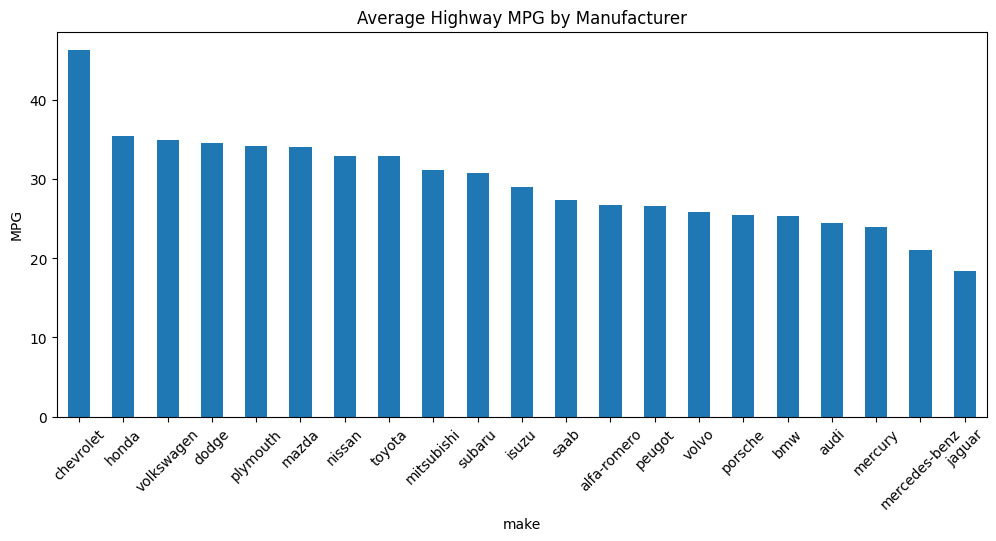

In [12]:
# Calculating average highway MPG by car manufacturer
avg_mpg_by_make = automobiles_df.groupby('make')['highway-mpg'].mean().sort_values(ascending=False)

# Display the series
avg_mpg_by_make

# Plot average highway MPG by manufacturer
avg_mpg_by_make.plot(kind='bar', figsize=(12,5), title='Average Highway MPG by Manufacturer')
plt.ylabel('MPG')
plt.xticks(rotation=45)
plt.show()




#### Which vehicles have the largest engine capacity.
Sort the dataframe based on the engine-size column.

In [13]:
# Getting top 10 cars with largest engine size
cols = ['make', 'body-style', 'engine-size', 'horsepower', 'price']

largest_engine = (
    automobiles_df.sort_values('engine-size', ascending=False)[cols]
)

# Display top 10 results
largest_engine.head(10)

,make,body-style,engine-size,horsepower,price
49,jaguar,sedan,326,262,36000
73,mercedes-benz,sedan,308,184,40960
74,mercedes-benz,hardtop,304,184,45400
47,jaguar,sedan,258,176,32250
48,jaguar,sedan,258,176,35550
71,mercedes-benz,sedan,234,155,34184
72,mercedes-benz,convertible,234,155,35056
17,bmw,sedan,209,182,36880
16,bmw,sedan,209,182,41315
15,bmw,sedan,209,182,30760


#### Which vehicle manufacturer has the most car models in the dataset

Number of car models per manufacturer:


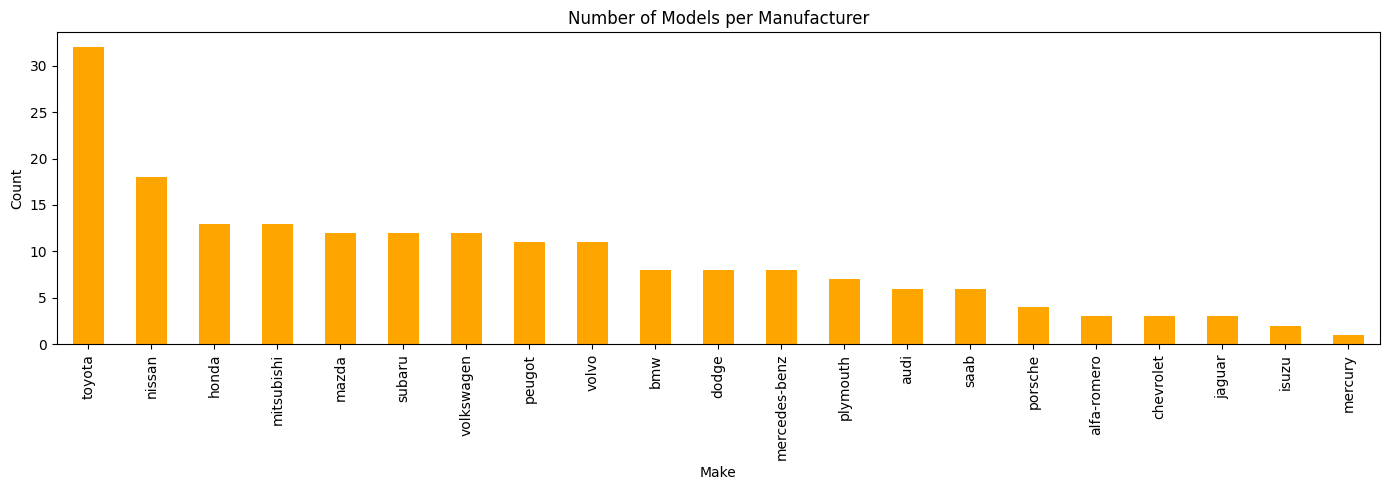


Manufacturer with most models: toyota
Number of models: 32


In [14]:
# Count number of models per manufacturer
models_per_make = automobiles_df['make'].value_counts()

# Display count and series
print("Number of car models per manufacturer:")
models_per_make

# Plot number of models per manufacturer
models_per_make.plot(
    kind='bar',
    figsize=(14, 5),
    color='orange'
)
plt.title('Number of Models per Manufacturer')
plt.ylabel('Count')
plt.xlabel('Make')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Print manufacturer with most models
print(f"\nManufacturer with most models: {models_per_make.index[0]}")
print(f"Number of models: {models_per_make.iloc[0]}")

